# [5.6] Linear Attention, RetNet and RWKV (solutions)

> **Colab: [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter5_modern_architectures/exercises/part6_linear_attention_retnet_rwkv/5.6_Linear_Attention_RetNet_and_RWKV_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter5_modern_architectures/exercises/part6_linear_attention_retnet_rwkv/5.6_Linear_Attention_RetNet_and_RWKV_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

# Introduction

Write `red → A`, then `blue → B`, then overwrite `red → C`. Ask for red. Should a memory answer A, C, or a mixture? A kernel memory adds writes; a decaying memory prefers recent writes. Neither property is a bug in isolation, but they imply different answers to this task.

By the end of this notebook, you will have shown that a fixed-size key–value memory can reproduce causal kernel attention, that recurrent and chunked retention reproduce its parallel equation, and that decay changes a controlled last-write recall answer relative to uniform attention and shuffled-value controls.

The task is deliberately small enough to calculate by hand. You will also implement the token shift, numerically stabilized weighted-key-value operator and channel mixing of an RWKV-4-style block. This is a mechanism study, not a language-model quality ranking. A recurrent state saves the growing key/value cache, but compresses information; parallelism does not make that compression disappear.

Prerequisites: [1.1] matrix attention and broadcasting, [0.3] numerical stability, and the recurrence/state perspective of [5.3]. Read the equations before optimizing them. All arrays below are CPU float64, with time first and channels last. No `torch.compile` is useful for these few dozen arithmetic operations.

**Study edition:** the default examples are deterministic CPU teaching fixtures. No pretrained model is loaded, no network is used, and no trained-model benchmark or native qualification is claimed. Save a personal copy.

## Content & Learning Objectives

### 1️⃣ A memory instead of an attention matrix

Build the operations below, check them on independent fixtures, and interpret the adjacent control.

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

### 2️⃣ Retention in three forms

Build the operations below, check them on independent fixtures, and interpret the adjacent control.

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

### 3️⃣ Inside an RWKV-4-style block

Build the operations below, check them on independent fixtures, and interpret the adjacent control.

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

### 4️⃣ What does the memory remember?

Build the operations below, check them on independent fixtures, and interpret the adjacent control.

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

### ☆ Bonus

Predict a changed condition, inspect an anomaly, and plan the paper-to-model bridge.

## Setup code

In [1]:
from pathlib import Path
import sys
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

chapter = "chapter5_modern_architectures"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
if str(exercises_dir) not in sys.path:
    sys.path.insert(0, str(exercises_dir))
import part6_linear_attention_retnet_rwkv.tests as tests

MAIN = __name__ == "__main__"
# NumPy arrays stay on CPU; float64 makes small analytic comparisons transparent.

# 1️⃣ A memory instead of an attention matrix

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

Softmax attention forms an entire row of weights for every query. Kernel attention chooses a feature map $\phi$ and replaces $\exp(q\cdot k)$ by $\phi(q)^\top\phi(k)$. This changes the kernel; it is not an algebraic identity with softmax. For nonnegative features the normalized causal readout is
$$y_t=\frac{\phi(q_t)^\top\sum_{s\leq t}\phi(k_s)v_s^\top}{\phi(q_t)^\top\sum_{s\leq t}\phi(k_s)}.$$
The numerator state has shape `(feature, value)` and the denominator state `(feature,)`. Their size is independent of sequence length. The full attention matrix costs quadratic storage if materialized; the states do not. We will prove equality of two implementations of **this** kernel before comparing it with softmax. Zero queries need a convention: return zero when the denominator is zero. Here nonnegative features make that a genuine no-match case, not signed cancellation.

Start with three writes. With one-hot red and blue keys, the two red values occupy the same memory row. Without forgetting, the readout averages them. A readout that returns the latest red value needs some additional recency or overwrite mechanism. The exercises distinguish these choices rather than calling every recurrence an equivalent transformer.

### Exercise - implement `positive_features`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement the positive feature map used in the linear-transformer paper: $\phi(x)=x+1$ for nonnegative inputs and $e^x$ otherwise. Preserve every axis. Avoid evaluating `exp` on very large positive entries just because `np.where` evaluates both branches. The exact zeros in later one-hot teaching keys are already nonnegative features; they do not need this transformation. Applying ELU+1 to those zeros would change the kernel and introduce cross-key similarities.

In [2]:
def positive_features(x):
    """ELU(x)+1, with no in-place mutation."""
    out = np.empty_like(np.asarray(x, dtype=float))
    mask = x >= 0
    out[mask] = x[mask] + 1
    out[~mask] = np.exp(x[~mask])
    return out


tests.test_positive_features(positive_features)

All tests in test_positive_features passed!


<details>
<summary>Hint</summary>

Allocate an output and fill each branch with a Boolean mask. A feature map changes the similarity function, not just the implementation.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_positive_features passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

### Exercise - implement `kernel_attention_parallel`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

`q,k` have shape `(time, feature)` and `v` `(time, value)`. Form the causal similarity matrix, normalize each row by its sum, then multiply by values. Include the current write. Use zero output for a row with zero mass. This deliberately quadratic implementation is our transparent baseline. Check time/feature shapes and reject negative features, since the denominator convention depends on positivity. Keep the causal mask on similarities, not on the already-averaged output.

In [3]:
def kernel_attention_parallel(q, k, v):
    """Causal normalized attention for supplied nonnegative features."""
    q,k,v = map(np.asarray,(q,k,v))
    if q.shape != k.shape or q.ndim != 2 or v.ndim != 2 or len(v) != len(q):
        raise ValueError("Expected matching time axes and q/k feature widths")
    if np.any(q<0) or np.any(k<0):
        raise ValueError("Normalized teaching kernel requires nonnegative features")
    weights = np.tril(q @ k.T)
    mass = weights.sum(axis=1,keepdims=True)
    weights = np.divide(weights,mass,out=np.zeros_like(weights,dtype=float),where=mass>0)
    return weights @ v


tests.test_kernel_attention_parallel(kernel_attention_parallel)

All tests in test_kernel_attention_parallel passed!


<details>
<summary>Hint</summary>

A lower-triangular matrix includes its diagonal. Use `np.divide(..., where=...)` to make the empty-match behavior explicit.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_kernel_attention_parallel passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

### Exercise - implement `kernel_attention_recurrent`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Now implement the same map using $S_t=S_{t-1}+k_tv_t^\top$ and $z_t=z_{t-1}+k_t$. Each step writes **before** reading, matching the causal diagonal above. Return `(outputs, S, z)` so the memory is inspectable. Do not store an attention matrix or call the parallel implementation. The fixture oracle enumerates allowed source positions independently. Causality is a semantic property: changing a future value must leave all earlier outputs unchanged.

In [4]:
def kernel_attention_recurrent(q, k, v):
    """Online normalized kernel attention with a fixed-size state."""
    q,k,v = map(np.asarray,(q,k,v))
    if q.shape != k.shape or q.ndim != 2 or v.ndim != 2 or len(v)!=len(q) or np.any(q<0) or np.any(k<0):
        raise ValueError("Invalid nonnegative time/feature inputs")
    state=np.zeros((k.shape[1],v.shape[1])); normalizer=np.zeros(k.shape[1]); outputs=[]
    for qt,kt,vt in zip(q,k,v):
        state += np.outer(kt,vt)
        normalizer += kt
        denom=qt @ normalizer
        outputs.append(qt @ state / denom if denom>0 else np.zeros(v.shape[1]))
    return np.asarray(outputs).reshape(len(q),v.shape[1]),state,normalizer


tests.test_kernel_attention_recurrent(kernel_attention_recurrent)

All tests in test_kernel_attention_recurrent passed!


<details>
<summary>Hint</summary>

The outer product writes a value vector into each key feature. A dot product `q @ S` reads those rows back.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_kernel_attention_recurrent passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

### Exercise - implement `causal_softmax_attention`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement row-wise softmax of $q_tk_s^\top/\tau$ for $s\leq t$. Subtract the allowed-row maximum before exponentiating and reject nonpositive temperature. Here `temperature` absorbs any dimension scaling: the task uses one-hot keys, so we keep the scale explicit. A repeated identical key receives the same content score at both positions. Softmax can sharpen content similarity, but it cannot choose the latest duplicate without a positional signal.

In [5]:
def causal_softmax_attention(q, k, v, temperature=1.0):
    """Stable causal softmax baseline, with no future leakage."""
    if temperature<=0:
        raise ValueError("temperature must be positive")
    out=[]
    for t,qt in enumerate(q):
        scores=qt @ k[:t+1].T / temperature
        weights=np.exp(scores-scores.max())
        out.append(weights @ v[:t+1] / weights.sum())
    return np.asarray(out)


tests.test_causal_softmax_attention(causal_softmax_attention)

All tests in test_causal_softmax_attention passed!


<details>
<summary>Hint</summary>

Slice keys and values to the current prefix before taking the maximum. Masking after a full softmax gives the wrong normalization.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_causal_softmax_attention passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

## Inspect the first memory row

,A,B,C
red→A,1.0,0.0,0.0
blue→B,0.0,1.0,0.0
red→C,0.5,0.0,0.5


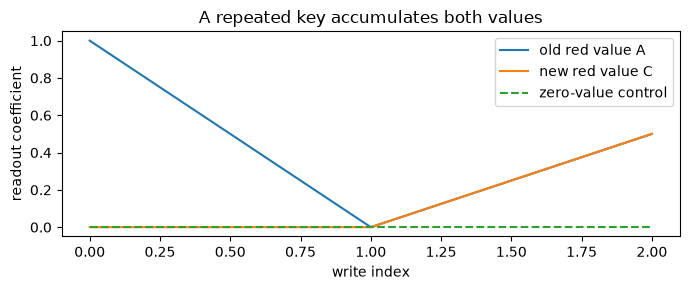

In [6]:
q=np.array([[1.,0.],[0.,1.],[1.,0.]])
v=np.eye(3)
reads,state,z=kernel_attention_recurrent(q,q,v)
display(pd.DataFrame(reads,index=["red→A","blue→B","red→C"],columns=["A","B","C"]))
fig,ax=plt.subplots(figsize=(7,3))
ax.plot(reads[:,0],label="old red value A");ax.plot(reads[:,2],label="new red value C")
ax.plot(kernel_attention_recurrent(q,q,np.zeros_like(v))[0][:,0],label="zero-value control",linestyle="--")
ax.set(xlabel="write index",ylabel="readout coefficient",title="A repeated key accumulates both values")
ax.legend();fig.tight_layout();plt.show()

<details>
<summary>Help - how should I interpret this?</summary>

After the third write the red readout gives A and C equal weight. The zero-value control stays zero. This is accumulation, not a learned overwrite policy. The displayed entries are coefficients, not sampled language tokens.

</details>

## Summary of 1️⃣

Parallel and recurrent kernel attention agree when the kernel, causal diagonal and normalization agree. Equality does not imply equivalence to softmax; it also does not solve conflicting writes.

# 2️⃣ Retention in three forms

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

Retention replaces an undamped sum by an exponentially weighted outer-product state. For real-valued supplied queries and keys, our single-head core is
$$S_t=\gamma S_{t-1}+k_tv_t^\top,\qquad y_t=q_t^\top S_t.$$
Expanding the recurrence gives $y_t=\sum_{s\leq t}\gamma^{t-s}(q_t^\top k_s)v_s$. Unlike the positive normalized attention above, this is an **unnormalized** bilinear operator and allows signed keys. Do not smuggle a softmax or row denominator into it. The original RetNet also uses positional complex rotations, multiple decays, normalization and learned gates; we expose the real core and a multi-scale composition here, with the complete released-stack parity pending.

A chunk is not a reset. At the beginning of a block, the previous state contributes to every within-block read, with an extra power of gamma at each step. By comparing non-divisible chunk lengths we can catch the common off-by-one and forgotten-carry errors. The final state has to match too: otherwise two implementations can agree on today's output and diverge at the next token.

### Exercise - implement `retention_parallel`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Inputs are `(time, key)` queries/keys and `(time, value)` values. Materialize the causal decay matrix $D_{ts}=\gamma^{t-s}$ for $s\leq t$ and zero otherwise; return `((q @ k.T) * D) @ v`. Restrict gamma to `[0,1]`. Gamma zero retains only the current write; gamma one is undamped accumulation. Avoid raising zero to negative powers in a masked array. These endpoint tests are better than checking a single random tensor.

In [7]:
def retention_parallel(q, k, v, gamma):
    """Unnormalized real retention with causal exponential weights."""
    if not 0<=gamma<=1:
        raise ValueError("gamma must lie in [0,1]")
    T=len(q);lag=np.arange(T)[:,None]-np.arange(T)[None,:]
    decay=np.where(lag>=0,gamma**np.maximum(lag,0),0.0)
    return ((q @ k.T)*decay) @ v


tests.test_retention_parallel(retention_parallel)

All tests in test_retention_parallel passed!


<details>
<summary>Hint</summary>

Compute integer lags, clip them before exponentiation, and separately zero the upper triangle.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_retention_parallel passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

### Exercise - implement `retention_recurrent`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return `(outputs, final_state)`. If an initial `(key,value)` matrix is supplied, copy it so a continuation does not mutate the caller's saved state. Decay the old state, add the current outer product, then read. This ordering gives the diagonal coefficient one. Test a continuation against a hand-enumerated history, not merely against another recurrence. Signed cancellation is valid here because no normalization divides by the query–key sum.

In [8]:
def retention_recurrent(q, k, v, gamma, initial=None):
    """Read and return a retained state, including continuation support."""
    if not 0<=gamma<=1:
        raise ValueError("gamma must lie in [0,1]")
    S=np.zeros((k.shape[1],v.shape[1])) if initial is None else np.array(initial,dtype=float,copy=True)
    out=[]
    for qt,kt,vt in zip(q,k,v):
        S=gamma*S+np.outer(kt,vt)
        out.append(qt @ S)
    return np.asarray(out).reshape(len(q),v.shape[1]),S


tests.test_retention_recurrent(retention_recurrent)

All tests in test_retention_recurrent passed!


<details>
<summary>Hint</summary>

One state update corresponds to one new time index. The initial carry has exponent `t+1`, while the current write has exponent zero.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_retention_recurrent passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

### Exercise - implement `retention_chunkwise`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Use chunk-local similarities for within-block writes and a carried state for the prefix. For local index $i$, incoming state contributes $\gamma^{i+1}q_i^\top S_{in}$. The outgoing state is $\gamma^B S_{in}+\sum_j\gamma^{B-1-j}k_jv_j^\top$. Return output and state for arbitrary positive chunk sizes, including a short final chunk. Do not call the recurrent implementation; the purpose is to derive the carry powers independently.

In [9]:
def retention_chunkwise(q, k, v, gamma, chunk_size):
    """Parallel within chunks, recurrent between chunks; return final state."""
    if chunk_size<1 or not 0<=gamma<=1:
        raise ValueError("Positive chunk and valid decay required")
    S=np.zeros((k.shape[1],v.shape[1]));outs=[]
    for start in range(0,len(q),chunk_size):
        qc,kc,vc=q[start:start+chunk_size],k[start:start+chunk_size],v[start:start+chunk_size]
        B=len(qc);lag=np.arange(B)[:,None]-np.arange(B)[None,:]
        D=np.where(lag>=0,gamma**np.maximum(lag,0),0.)
        outs.append(((qc@kc.T)*D)@vc+(qc@S)*gamma**np.arange(1,B+1)[:,None])
        S=gamma**B*S+kc.T @ (vc*gamma**np.arange(B-1,-1,-1)[:,None])
    return np.concatenate(outs),S


tests.test_retention_chunkwise(retention_chunkwise)

All tests in test_retention_chunkwise passed!


<details>
<summary>Hint</summary>

Write the formula for a two-token chunk on paper. The first token sees gamma times incoming memory, not the un-decayed memory.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_retention_chunkwise passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

### Exercise - implement `decay_horizon`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Convert each decay to a readable horizon using $\lceil\log(\epsilon)/\log(\gamma)\rceil$. Gamma zero has horizon one (only the current write survives); gamma one has infinite horizon. This is a coefficient threshold, not an effective language-model context window. A learned key or readout may amplify or cancel the contribution. Keeping this distinction matters when interpreting per-head decay spectra.

In [10]:
def decay_horizon(gammas, remaining=0.01):
    """Smallest integer lag whose retained coefficient is at most remaining."""
    g=np.asarray(gammas,dtype=float)
    if np.any((g<0)|(g>1)) or not 0<remaining<1:
        raise ValueError("Invalid decay or threshold")
    out=np.full(g.shape,np.inf);out[g==0]=1
    mask=(g>0)&(g<1)
    out[mask]=np.ceil(np.log(remaining)/np.log(g[mask]))
    return out


tests.test_decay_horizon(decay_horizon)

All tests in test_decay_horizon passed!


<details>
<summary>Hint</summary>

Treat exact endpoints separately before taking logarithms. A horizon is about a specified attenuation threshold.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_decay_horizon passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

## One operator, three implementations

,parallel,recurrent,chunked,reset-at-every-token control
0,0.0000,0.0000,0.0000,0.0
1,0.2000,0.2000,0.2000,0.2
2,0.4000,0.4000,0.4000,0.4
3,1.5780,1.5780,1.5780,1.2
4,1.2886,1.2886,1.2886,0.8


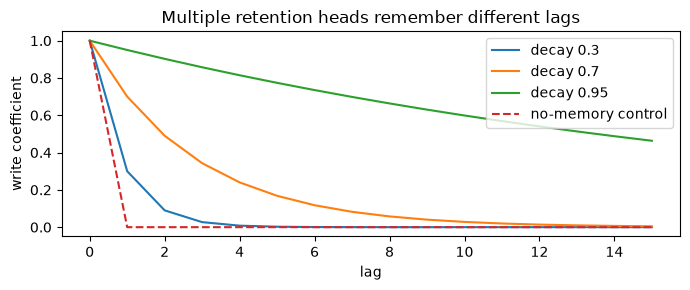

parallel/recurrent max error 2.220446049250313e-16
parallel/chunked max error 2.220446049250313e-16


In [11]:
q=np.array([[1.,0.],[0.,1.],[1.,0.],[1.,1.],[0.,1.]])
k=q.copy();v=np.arange(10.).reshape(5,2)/10
parallel=retention_parallel(q,k,v,.7)
recurrent,state=retention_recurrent(q,k,v,.7)
chunked,last=retention_chunkwise(q,k,v,.7,2)
display(pd.DataFrame({"parallel":parallel[:,0],"recurrent":recurrent[:,0],"chunked":chunked[:,0],"reset-at-every-token control":retention_parallel(q,k,v,0)[:,0]}))
fig,ax=plt.subplots(figsize=(7,3))
for gamma in [.3,.7,.95]:ax.plot(gamma**np.arange(16),label=f"decay {gamma}")
ax.plot(np.r_[1.,np.zeros(15)],label="no-memory control",linestyle="--")
ax.set(xlabel="lag",ylabel="write coefficient",title="Multiple retention heads remember different lags");ax.legend();fig.tight_layout();plt.show()
print("parallel/recurrent max error",np.max(np.abs(parallel-recurrent)))
print("parallel/chunked max error",np.max(np.abs(parallel-chunked)))

<details>
<summary>Help - how should I interpret this?</summary>

The first three table columns agree up to float64 rounding. The reset control loses older writes. Slow decay retains longer coefficients, but says nothing by itself about trained retrieval accuracy. Multiple heads can carry different gammas; mixing them is learned in the full model.

</details>

## Summary of 2️⃣

Retention is an unnormalized decaying bilinear map. Chunking changes the schedule, not its function; resetting memory changes the function. Coefficient horizons should not be advertised as measured model context lengths.

# 3️⃣ Inside an RWKV-4-style block

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

RWKV is not just retention with a different name. Its time-mixing module combines a token shift, channel-specific weighted histories, a special current-token bonus and a receptance gate. Its channel-mixing module uses a squared-ReLU expansion and another receptance. We implement these operations with supplied weights, then compose one pre-normalized residual block.

For each channel, let $a,b$ store the numerator and denominator of previous writes, $d\in(0,1]$ their decay and $u$ the current-token bonus. Before the update the output is $(a+e^{u+k_t}v_t)/(b+e^{u+k_t})$; afterwards $a\leftarrow da+e^{k_t}v_t$ and $b\leftarrow db+e^{k_t}$. Direct exponentials overflow for large keys. Keep a shared log scale $p$ so stored `a,b` remain scaled, and use maxima to change scale without changing their ratio. The current bonus affects the read, not the stored history.

The exercises use `(time,channel)` arrays and distinct key/value/receptance projection matrices. A complete checkpoint includes embedding, repeated blocks, all learned mixes/decays, normalization epsilon, output head and implementation-specific stabilization. We do not claim native parity from this one block. The paper and official implementation are the bridge specification, not a license to guess a checkpoint layout.

### Exercise - implement `time_mix`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return `mix*x + (1-mix)*previous_x`. `mix` broadcasts over channels; time zero uses a zero previous vector. The shift is causal: `np.roll` alone wraps the last token into the first and leaks future information. Test the two endpoint mixes as well as a nonuniform channel mix. RWKV learns different mixes for key, value and receptance, so this operation is used more than once.

In [12]:
def time_mix(x, mix):
    """Mix current and previous token, with zero initial previous input."""
    previous=np.concatenate([np.zeros_like(x[:1]),x[:-1]],axis=0)
    return mix*x+(1-mix)*previous


tests.test_time_mix(time_mix)

All tests in test_time_mix passed!


<details>
<summary>Hint</summary>

Concatenate an explicit zero row with all but the final input row.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_time_mix passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

### Exercise - implement `rwkv_wkv`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the full `(time,channel)` weighted-value sequence. `decay` and `bonus` broadcast over channels. Maintain scaled numerator `a`, denominator `b`, and log scale `p`, initially zero, zero and negative infinity. For the read use `max(p, bonus+k)`; for the update use `max(p+log(decay), k)`. Reject decay outside `(0,1]`. A fixture with keys near 1000 must remain finite. Do not apply the current-token bonus to memory storage.

In [13]:
def rwkv_wkv(keys, values, decay, bonus):
    """Stable channelwise RWKV-4 WKV read and update."""
    decay=np.asarray(decay)
    if np.any((decay<=0)|(decay>1)):
        raise ValueError("decay must be in (0,1]")
    a=np.zeros(values.shape[1]);b=np.zeros_like(a);p=np.full_like(a,-np.inf);out=[]
    for key,value in zip(keys,values):
        r=bonus+key;scale=np.maximum(p,r)
        old=np.exp(p-scale);new=np.exp(r-scale)
        out.append((old*a+new*value)/(old*b+new))
        next_scale=np.maximum(p+np.log(decay),key)
        old=np.exp(p+np.log(decay)-next_scale);new=np.exp(key-next_scale)
        a=old*a+new*value;b=old*b+new;p=next_scale
    return np.asarray(out)


tests.test_rwkv_wkv(rwkv_wkv)

All tests in test_rwkv_wkv passed!


<details>
<summary>Hint</summary>

Rescale numerator and denominator together. Subtracting the same maximum from all log weights preserves a weighted average.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_rwkv_wkv passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

### Exercise - implement `rwkv_channel_mix`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

`xk,xr` are already shifted/mixed `(time,model)` inputs, `Wk` is `(model,hidden)`, `Wv` `(hidden,model)` and `Wr` `(model,model)`. Compute `sigmoid(xr@Wr) * (relu(xk@Wk)**2 @ Wv)`. Do not square negative preactivations before rectifying: that would turn suppressed features into positive ones. This is a channel transformation, not a time-memory update.

In [14]:
def rwkv_channel_mix(xk, xr, Wk, Wv, Wr):
    """Squared-ReLU channel expansion with a receptance gate."""
    receptance=1/(1+np.exp(-(xr@Wr)))
    hidden=np.maximum(xk@Wk,0)**2
    return receptance*(hidden@Wv)


tests.test_rwkv_channel_mix(rwkv_channel_mix)

All tests in test_rwkv_channel_mix passed!


<details>
<summary>Hint</summary>

With a zero receptance matrix the sigmoid gate is exactly one half, which makes a useful hand calculation.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_rwkv_channel_mix passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

### Exercise - implement `rwkv_block`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Compose the taught operations with explicit supplied weights. The dictionary contains `mix_k,mix_v,mix_r,mix_ck,mix_cr,decay,bonus,K,V,R,O,CK,CV,CR`. Use featurewise layer normalization with epsilon `1e-5`, then a time-mixing residual, then a newly normalized channel-mixing residual. Learned normalization affine parameters are fixed to identity here; checkpoint parity remains pending. Keep both residual additions visible: a zero output projection must make its branch an identity, regardless of the hidden state.

In [15]:
def rwkv_block(x, weights):
    """One pre-normalized RWKV-4-style time/channel residual block."""
    def norm(z):
        return (z-z.mean(-1,keepdims=True))/np.sqrt(z.var(-1,keepdims=True)+1e-5)
    z=norm(x);w=weights
    k=time_mix(z,w["mix_k"])@w["K"]
    v=time_mix(z,w["mix_v"])@w["V"]
    r=1/(1+np.exp(-(time_mix(z,w["mix_r"])@w["R"])))
    y=x+(r*rwkv_wkv(k,v,w["decay"],w["bonus"]))@w["O"]
    z=norm(y)
    return y+rwkv_channel_mix(time_mix(z,w["mix_ck"]),time_mix(z,w["mix_cr"]),w["CK"],w["CV"],w["CR"])


tests.test_rwkv_block(rwkv_block)

All tests in test_rwkv_block passed!


<details>
<summary>Hint</summary>

The layer normalization after the time residual sees the updated stream. Use the branch-zero tests to isolate composition errors.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_rwkv_block passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

## What does a current-token bonus do?

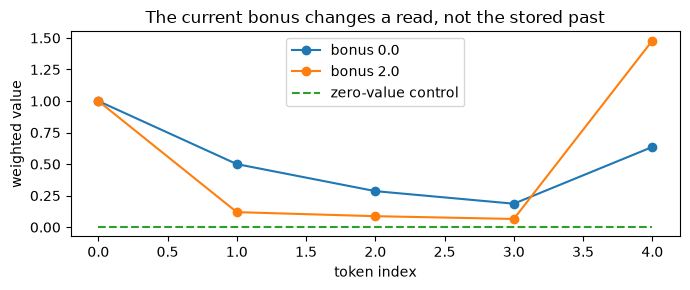

In [16]:
keys=np.zeros((5,1));values=np.array([[1.],[0.],[0.],[0.],[2.]])
fig,ax=plt.subplots(figsize=(7,3))
for bonus in [0.,2.]:ax.plot(rwkv_wkv(keys,values,.8,bonus)[:,0],marker="o",label=f"bonus {bonus}")
ax.plot(rwkv_wkv(keys,np.zeros_like(values),.8,0)[:,0],label="zero-value control",linestyle="--")
ax.set(xlabel="token index",ylabel="weighted value",title="The current bonus changes a read, not the stored past");ax.legend();fig.tight_layout();plt.show()

<details>
<summary>Help - how should I interpret this?</summary>

The current value has more influence when its bonus is larger. At token zero both nonzero paths return the same value because there is no competing history. This is a hand-specified scalar channel, not an RWKV checkpoint generation.

</details>

## Summary of 3️⃣

Token shifts, stable WKV, receptance and squared-ReLU channel mixing define distinct operations. A single residual block teaches their composition; it does not establish a complete released model or generation parity.

# 4️⃣ What does the memory remember?

> ##### Learning Objectives
>
> - Implement the stated mechanism and explain its shape conventions.
> - Compare an actual task measurement with its control.

Now return to the overwrite puzzle. We freeze twelve three-write episodes: old red value A, B, C or D; a blue distractor; and a different new red value. All ordered unequal old/new value pairs occur once, so tie-breaking cannot favor the newest value systematically. Keys are exact one-hot tags. Each episode is a deterministic unit illustration, not a training/test benchmark.

Compare four readouts on the same writes and query: undamped normalized kernel attention, retention with gamma 0.5, softmax content attention with temperature 0.1 and retention after shuffling the values. Decode by `argmax`, with NumPy's first-index tie rule. We care about both the token and the underlying coefficients: an answer can be correct because of a tie rule. Shuffled values are a broken-binding control, not another memory architecture.

### Exercise - implement `last_write_episodes`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return a list of dictionaries containing `keys` `(3,2)`, `values` `(3,n_values)`, `query` `(2,)` and integer `answer`. Keys are red, blue, red. For each ordered old/new pair, choose the distractor `(old+1)%n_values`. The target is the newest red value. Require at least two values. This explicit generator lets you inspect every evaluation item rather than relying on an opaque task helper.

In [17]:
def last_write_episodes(n_values=4):
    """Enumerate all unequal old/new value pairs with a distractor."""
    if n_values<2:
        raise ValueError("Need at least two values")
    episodes=[]
    for old in range(n_values):
        for new in range(n_values):
            if old==new:continue
            episodes.append(dict(keys=np.array([[1.,0.],[0.,1.],[1.,0.]]),values=np.eye(n_values)[[old,(old+1)%n_values,new]],query=np.array([1.,0.]),answer=new))
    return episodes


tests.test_last_write_episodes(last_write_episodes)

All tests in test_last_write_episodes passed!


<details>
<summary>Hint</summary>

Enumerate ordered pairs, not combinations. We need both directions to expose the argmax tie rule.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_last_write_episodes passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

### Exercise - implement `shuffle_values`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Copy the input and permute time rows using a local NumPy generator. Preserve each complete value vector, its multiset and the original array. This control can coincidentally keep an answer correct; report its actual value rather than insisting it be zero. A shuffle is not guaranteed to have no fixed points.

In [18]:
def shuffle_values(values, seed=0):
    """Break key/value binding by permuting complete value rows."""
    order=np.random.default_rng(seed).permutation(len(values))
    return np.array(values[order],copy=True)


tests.test_shuffle_values(shuffle_values)

All tests in test_shuffle_values passed!


<details>
<summary>Hint</summary>

Shuffle row indices once. Shuffling each value channel separately creates invalid mixtures rather than a broken-binding control.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_shuffle_values passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

### Exercise - implement `recall_accuracy`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

`scores` has shape `(episodes,values)` and `answers` `(episodes,)`. Return correct count divided by the number of episodes. Reject an empty cohort or inconsistent axes. `np.argmax` chooses the first maximum; keep this rule fixed. The complete score table will reveal ties, so an apparently successful result cannot hide ambiguity behind a single percentage.

In [19]:
def recall_accuracy(scores, answers):
    """Top-1 accuracy with first-index tie breaking and explicit denominator."""
    scores=np.asarray(scores);answers=np.asarray(answers)
    if scores.ndim!=2 or len(scores)==0 or answers.shape!=(len(scores),) or not np.isfinite(scores).all() or np.any((answers<0)|(answers>=scores.shape[1])):
        raise ValueError("Invalid recall cohort")
    return float(np.mean(scores.argmax(-1)==answers))


tests.test_recall_accuracy(recall_accuracy)

All tests in test_recall_accuracy passed!


<details>
<summary>Hint</summary>

The denominator is all frozen episodes, including ties and failures. Do not filter to cases a method already answers correctly.

</details>

<details>
<summary>Expected output</summary>

The independent fixture should print `All tests in test_recall_accuracy passed!`. Passing this check validates the stated small-case semantics, not a released model.

</details>

## Signature result — twelve overwrite queries

,old,new/target,kernel average,retention γ=.5,softmax content,shuffled bindings
0,A,B,A,B,B,B
1,A,C,A,C,A,C
2,A,D,A,D,A,B
3,B,A,A,A,A,B
4,B,C,B,C,C,C
5,B,D,B,D,B,B
6,C,A,A,A,A,A
7,C,B,B,B,B,D
8,C,D,C,D,D,C
9,D,A,A,A,A,A


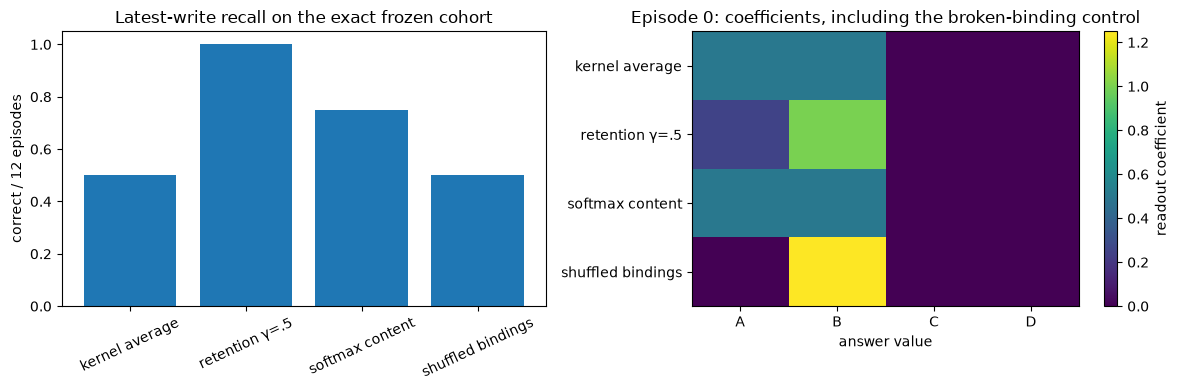

{'kernel average': 0.5, 'retention γ=.5': 1.0, 'softmax content': 0.75, 'shuffled bindings': 0.5}


In [20]:
episodes=last_write_episodes();names=["kernel average","retention γ=.5","softmax content","shuffled bindings"]
all_scores={name:[] for name in names};rows=[]
for index,e in enumerate(episodes):
    qs=np.repeat(e["query"][None,:],3,axis=0);k,v=e["keys"],e["values"]
    scores=[kernel_attention_parallel(qs,k,v)[-1],retention_parallel(qs,k,v,.5)[-1],causal_softmax_attention(qs,k,v,.1)[-1],retention_parallel(qs,k,shuffle_values(v,index),.5)[-1]]
    rows.append({"old":chr(65+v[0].argmax()),"new/target":chr(65+e["answer"]),**{name:chr(65+score.argmax()) for name,score in zip(names,scores)}})
    for name,score in zip(names,scores):all_scores[name].append(score)
answers=np.array([e["answer"] for e in episodes]);accuracies=[recall_accuracy(np.array(all_scores[name]),answers) for name in names]
display(pd.DataFrame(rows))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].bar(names,accuracies);axes[0].set(ylim=(0,1.05),ylabel="correct / 12 episodes",title="Latest-write recall on the exact frozen cohort");axes[0].tick_params(axis="x",rotation=25)
matrix=np.array([all_scores[name][0] for name in names]);im=axes[1].imshow(matrix,aspect="auto",cmap="viridis");axes[1].set(xticks=range(4),xticklabels=list("ABCD"),yticks=range(4),yticklabels=names,xlabel="answer value",title="Episode 0: coefficients, including the broken-binding control");fig.colorbar(im,ax=axes[1],label="readout coefficient")
fig.tight_layout();plt.show()
print(dict(zip(names,accuracies)))

<details>
<summary>Help - how should I interpret this?</summary>

Undamped kernel attention ties old and new red values, so its exact-cohort accuracy is one half under the frozen tie rule. Retention weights the newest red write more. Softmax distinguishes red from blue but cannot distinguish identical red keys by recency here. The shuffled condition may retain some answers by coincidence; its measured bar is the control. These are consequences of the explicit equations on twelve items, not trained architecture rankings.

</details>

## Interpreting the result

The measured accuracies are 6/12 for the kernel average, 12/12 for retention, 9/12 for softmax and 6/12 for the frozen shuffled bindings. Why does content softmax beat the kernel average despite assigning identical scores to both red writes? Its tiny but nonzero blue weight sometimes adds to the newest red value, breaking three otherwise-wrong ties. Inspect the actual coefficients and answer identities. This is distractor-value overlap, not a learned recency rule; excluding those episodes after seeing the result would change the cohort.

Fixed-state memory size and successful recall are different questions. Query/key geometry controls interference between different keys; decay controls competition between different times. Content-only softmax has its own duplicate-key ambiguity. The RWKV channel experiment isolates time weighting but is not included as a task-trained model competitor: its learned projections and gates have not been fitted.

## Try it yourself

Predict what changing only retention gamma from 0.5 to 1 will do to the overwrite advantage. Keep the cohort, tie rule and value ordering fixed. Separately try a query for blue: does forgetting help when its only write is older?

In [21]:
play_gamma=1.0
e=last_write_episodes()[0]
play_query=np.array([0.,1.])  # change only one condition at a time
q=np.repeat(play_query[None,:],3,axis=0)
display(pd.DataFrame({"retention":retention_parallel(q,e["keys"],e["values"],play_gamma)[-1],"kernel baseline":kernel_attention_parallel(q,e["keys"],e["values"])[-1],"zero-write control":retention_parallel(q,e["keys"],np.zeros_like(e["values"]),play_gamma)[-1]},index=list("ABCD")))

,retention,kernel baseline,zero-write control
A,0.0,0.0,0.0
B,1.0,1.0,0.0
C,0.0,0.0,0.0
D,0.0,0.0,0.0


## Limitations

| Topic | Taught here | Not covered here |
| --- | --- | --- |
| Linear attention | Positive feature map, normalized parallel/recurrent equality, causal softmax comparison and exact recall task | Trained recall capacity across dimensions/lengths and measured performance |
| RetNet | Real retention parallel/recurrent/chunkwise forms; independent heads can use separate decays; coefficient spectrum | Complex positional rotations, complete learned multi-scale gated RetNet stack, training and released parity |
| RWKV | Token shift, stable channelwise WKV, receptance, squared-ReLU channel mixing and a supplied-weight RWKV-4-style residual block | Load the explicitly versioned `RWKV/rwkv-4-169m-pile` tokenizer/checkpoint, map every parameter, compare full/prefill/token-state outputs and generation to the official implementation |

The bridge is an implementation boundary, not a call to download weights. Record exact revision, dtype, normalization and cache/reset rules before a later native parity run. No such budget is allocated here. NumPy reference arithmetic is not fused-kernel performance evidence.

# ☆ Bonus

## Anomaly hunt

Why can a random value shuffle occasionally score better than one half on twelve cases? Inspect its actual permutation and repeated labels. How would you distinguish a key collision from a stale-write error? Propose a changed **task**, such as first-write recall, rather than just a new seed. Predict which recency preference would then be harmful before calculating it.

## Further reading

- [Transformers are RNNs: Fast Autoregressive Transformers with Linear Attention](https://arxiv.org/abs/2006.16236): positive-kernel normalization and recurrent states.
- [Retentive Network](https://arxiv.org/abs/2307.08621): retention, multi-scale heads and three computation schedules.
- [RWKV: Reinventing RNNs for the Transformer Era](https://arxiv.org/abs/2305.13048): token shift, WKV and channel mixing.
- [Official RWKV-LM implementation](https://github.com/BlinkDL/RWKV-LM): inspect the version-specific block and stabilization before a native bridge.